# Respond to Events

This example measures how quickly a concept responds to events, such as fires, floods, or volcanic eruptions: the time from an event's onset to the first observation of its place (its first look), and to the delivery of that observation's data to the ground. It compares a satellite that images everything in a wide swath with an agile satellite that turns its body to point a narrow, high-resolution imager at one requested target at a time, and must slew between targets.

The events are synthetic: points over the western United States whose onsets are random over three days, each of interest for two days, with random priorities. The concept is a constellation of four satellites in sun-synchronous orbits at 500 km, which image only sunlit targets and downlink to the stations of Kongsberg Satellite Services (KSAT) in NASA's Near Earth Network.

In [1]:
import warnings
from datetime import datetime, timedelta, timezone

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import Point

start = datetime(2026, 7, 1, tzinfo=timezone.utc)
end = start + timedelta(days=5)
hour = timedelta(hours=1)
BLUE, ORANGE, AQUA, GRAY, INK = "#257de0", "#f47230", "#00b894", "#8a8984", "#191919"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
    }
)

## The events

Each event has a place (its geometry, a point), an `onset`, an `expires` time after which observations no longer count, and a `priority` (higher first). The analysis functions match observations to events by place, as they match observations to targets.

In [2]:
rng = np.random.default_rng(42)
count = 150
events = gpd.GeoDataFrame(
    {
        "onset": [start + timedelta(hours=h) for h in rng.uniform(0, 72, count)],
        "priority": rng.integers(1, 4, count),
    },
    geometry=[
        Point(x, y)
        for x, y in zip(rng.uniform(-124, -104, count), rng.uniform(32, 48, count))
    ],
    crs="EPSG:4326",
)
events["expires"] = events["onset"] + timedelta(hours=48)
events.head()

,onset,priority,geometry,expires
0,2026-07-03 07:43:29.407786+00:00,2,POINT (-105.50383 34.36453),2026-07-05 07:43:29.407786+00:00
1,2026-07-02 07:35:57.291584+00:00,3,POINT (-123.50281 46.97804),2026-07-04 07:35:57.291584+00:00
2,2026-07-03 13:49:08.580841+00:00,1,POINT (-112.89604 39.00646),2026-07-05 13:49:08.580841+00:00
3,2026-07-03 02:12:37.793132+00:00,3,POINT (-111.3205 38.13312),2026-07-05 02:12:37.793132+00:00
4,2026-07-01 06:46:50.768572+00:00,2,POINT (-121.88205 43.67497),2026-07-03 06:46:50.768572+00:00


## The concepts

Both concepts fly four satellites in four sun-synchronous planes (crossing the equator at 10:30, 16:30, 22:30, and 04:30 local time) and reach 30 degrees from nadir. The wide imager sees a 60-degree swath at once, so it images every sunlit event within reach without tasking. The narrow imager sees 1 degree, about 9 km at nadir, and must point at each target: its 60-degree field of regard is the reach of the body's slews.

In [3]:
from tatc.catalog import get_system
from tatc.schemas import PointedInstrument, SunSynchronousOrbit, WalkerConstellation


def constellation(instrument):
    return WalkerConstellation(
        name="sat",
        orbit=SunSynchronousOrbit(
            altitude=500e3, equator_crossing_time="10:30", epoch=start
        ),
        instruments=[instrument],
        number_satellites=4,
        number_planes=4,
    ).generate_members()


wide = PointedInstrument(
    name="wide imager",
    field_of_regard=60,
    cross_track_field_of_view=60,
    along_track_field_of_view=1,
    req_target_sunlit=True,
)
narrow = PointedInstrument(
    name="narrow imager",
    field_of_regard=60,
    cross_track_field_of_view=1,
    along_track_field_of_view=1,
    req_target_sunlit=True,
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # the catalog's KSAT stations are nominal
    stations = get_system("near_earth_network").build("ksat")
[station.name for station in stations]

['SG1', 'SG2', 'SG3', 'TR2', 'TR3', 'SI1']

## Without tasking

The wide imager's observations of the events' places (`collect_observations`), with the latency of each to the next contact with a KSAT station (`collect_downlinks` and `compute_latencies`), give each event's response (`compute_event_responses`): its first look after its onset (and before it expires), the time from its onset to then, and the earliest delivery of its looks' data.

In [4]:
from tatc.analysis import (
    collect_downlinks,
    collect_observations,
    compute_event_responses,
    compute_latencies,
)

wide_satellites = constellation(wide)
looks = collect_observations(events.geometry, wide_satellites, start, end)
downlinks = collect_downlinks(stations, wide_satellites, start, end + timedelta(days=1))
latencies = compute_latencies(looks, downlinks)
responses = {
    "wide swath": compute_event_responses(latencies, events, time_column="observed")
}
responses["wide swath"][
    ["onset", "priority", "first_look", "response", "looks", "delivery"]
].head()

,onset,priority,first_look,response,looks,delivery
0,2026-07-03 07:43:29.407786+00:00,2,2026-07-03 23:03:02.409680338+00:00,0 days 15:19:33.001894338,1,0 days 16:19:13.174126
1,2026-07-02 07:35:57.291584+00:00,3,2026-07-02 19:07:12.718406566+00:00,0 days 11:31:15.426822566,4,0 days 12:51:30.625013
2,2026-07-03 13:49:08.580841+00:00,1,2026-07-04 18:25:09.126102781+00:00,1 days 04:36:00.545261781,1,1 days 05:54:26.661502
3,2026-07-03 02:12:37.793132+00:00,3,2026-07-03 12:29:11.168438137+00:00,0 days 10:16:33.375306137,2,0 days 11:34:51.914566
4,2026-07-01 06:46:50.768572+00:00,2,2026-07-01 13:11:52.445338842+00:00,0 days 06:25:01.676766842,2,0 days 07:04:19.501941


## With tasking

The agile satellites image requests one at a time (`schedule_tasks`). Each request's opportunities are the periods in which a satellite may point at its target, sunlit, between its onset and expiry (`collect_imaging_opportunities`). Requests are scheduled in order of priority, then of expiry and onset, each at the earliest time on any satellite that leaves time to slew from its previous image and to its next, holding its view on the target for 10 s. The time to slew follows the satellite's `Agility`: its maximum rate, maximum acceleration, and settle time.

Two agilities bracket small agile satellites: a slow one (0.5 deg/s, 0.1 deg/s², 15 s to settle) and a fast one (3 deg/s, 1 deg/s², 5 s).

In [5]:
from tatc.analysis import schedule_tasks
from tatc.schemas import Agility

narrow_satellites = constellation(narrow)
narrow_downlinks = collect_downlinks(
    stations, narrow_satellites, start, end + timedelta(days=1)
)
agilities = {
    "agile, slow": Agility(max_rate=0.5, max_acceleration=0.1, settle_time=15),
    "agile, fast": Agility(max_rate=3, max_acceleration=1, settle_time=5),
}
plans = {}
for name, agility in agilities.items():
    plans[name] = schedule_tasks(
        narrow_satellites, events, start, end, agility, dwell=timedelta(seconds=10)
    )
    images = compute_latencies(plans[name].observations, narrow_downlinks)
    responses[name] = compute_event_responses(images, events, time_column="observed")
pd.DataFrame(
    {
        name: {"images": len(plan.observations), "unscheduled": len(plan.unscheduled)}
        for name, plan in plans.items()
    }
).T

,images,unscheduled
"agile, slow",74,76
"agile, fast",129,21


Each plan gives its images as observations, with the angles of the body that point at each target and the slew to it, and the attitude of each satellite over time (`TaskingPlan.attitudes`). The slow satellite takes about 50 s for its median slew of 14 degrees; the fast one takes about 16 s, a third of the time, for its median slew of 25 degrees, as it reaches farther between targets in the time it saves.

In [6]:
pd.DataFrame(
    {
        name: {
            "median slew (deg)": plan.observations["slew_angle"].median(),
            "median slew time (s)": plan.observations["slew_time"].median()
            / timedelta(seconds=1),
            "median off-nadir (deg)": plan.observations["off_nadir"].median(),
        }
        for name, plan in plans.items()
    }
).T.round(1)

,median slew (deg),median slew time (s),median off-nadir (deg)
"agile, slow",14.3,48.6,27.3
"agile, fast",24.7,16.2,27.1


## Responses

The wide swath sees nearly every event, most within a day of its onset; its first looks wait only for a sunlit pass. The narrow imager, tasked, sees fewer: within a pass, it can image only as many crowded targets as its slews allow, and an event left unimaged for two days expires. Agility recovers most of the difference, and the priorities protect the most important events. Delivery adds about an hour, the wait for a pass over a KSAT station at high latitude.

In [7]:
pd.DataFrame(
    {
        name: {
            "seen (%)": 100 * (result["looks"] > 0).mean(),
            "seen, priority 3 (%)": 100
            * (result.loc[result["priority"] == 3, "looks"] > 0).mean(),
            "median response (h)": result["response"].median() / hour,
            "90th percentile response (h)": result["response"].quantile(0.9) / hour,
            "median delivery (h)": result["delivery"].median() / hour,
        }
        for name, result in responses.items()
    }
).T.round(1)

,seen (%),"seen, priority 3 (%)",median response (h),90th percentile response (h),median delivery (h)
wide swath,97.3,98.0,11.1,29.0,12.0
"agile, slow",49.3,80.4,18.9,41.4,19.9
"agile, fast",86.0,98.0,15.5,38.7,16.8


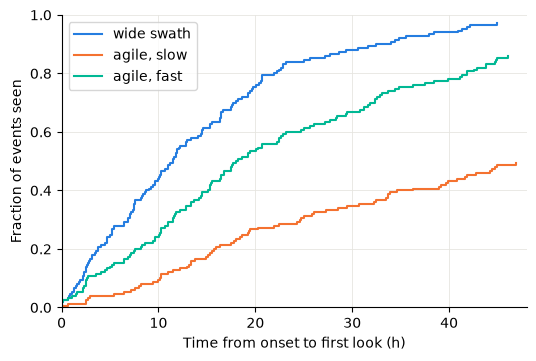

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.8))
for (name, result), color in zip(responses.items(), (BLUE, ORANGE, AQUA)):
    hours = np.sort(result["response"].dropna() / hour)
    fraction = np.arange(1, len(hours) + 1) / len(result)
    ax.step(hours, fraction, where="post", color=color, label=name)
ax.set_xlabel("Time from onset to first look (h)")
ax.set_ylabel("Fraction of events seen")
ax.set_xlim(0, 48)
ax.set_ylim(0, 1)
ax.legend()
plt.show()

## Responses to events at any time

Given events answer for one draw of onsets. `compute_response_statistics` instead gives, for each place, the exact distribution of the wait from an onset at any time of a period to the next look (or, with `delivered=True`, to the delivery of a look's data): an onset in a gap between looks waits for the next look, so long gaps count more than in a mean revisit. Places farther north, where the swaths of the sun-synchronous orbits overlap, wait less; some places farther south fall between swaths on some days, and wait more than a day.

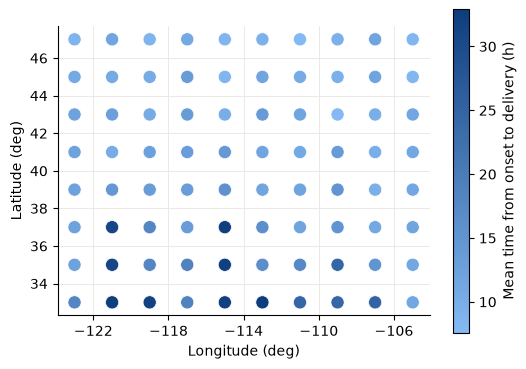

In [9]:
from matplotlib.colors import LinearSegmentedColormap

from tatc.analysis import compute_response_statistics

grid = gpd.GeoDataFrame(
    geometry=[
        Point(x, y) for x in np.arange(-123, -104, 2.0) for y in np.arange(33, 48, 2.0)
    ],
    crs="EPSG:4326",
)
grid_looks = collect_observations(grid.geometry, wide_satellites, start, end)
statistics = compute_response_statistics(
    compute_latencies(grid_looks, downlinks),
    start,
    start + timedelta(days=3),
    deadline=timedelta(hours=12),
    delivered=True,
    targets=grid,
    time_column="observed",
)
fig, ax = plt.subplots(figsize=(6, 4.2))
points = ax.scatter(
    statistics.geometry.x,
    statistics.geometry.y,
    c=statistics["response"] / hour,
    cmap=LinearSegmentedColormap.from_list("blues", ["#84b9f3", "#0e3d7e"]),
    s=90,
    edgecolors="white",
    linewidths=0.5,
)
fig.colorbar(points, ax=ax, label="Mean time from onset to delivery (h)")
ax.set_xlabel("Longitude (deg)")
ax.set_ylabel("Latitude (deg)")
ax.set_xticks(np.arange(-122, -103, 4))
ax.set_aspect("equal")
plt.show()

In [10]:
statistics[
    [
        "responded",
        "response",
        "response p50",
        "response p90",
        "max_response",
        "within_deadline",
    ]
].describe().loc[["mean", "min", "max"]]

,responded,response,response p50,response p90,max_response,within_deadline
mean,0.99967,0 days 14:50:17.410642900,0 days 13:11:58.487833896,1 days 05:11:30.714140656,1 days 12:03:43.089568530,0.513468
min,0.98673,0 days 07:35:50.089147567,0 days 06:42:40.652463657,0 days 14:16:38.456943359,0 days 17:52:44.571215432,0.169653
max,1.00000,1 days 08:55:21.010019864,1 days 07:27:03.098886350,2 days 12:15:13.284809736,2 days 19:27:13.284809736,0.801618
